# 09_14 Uncertainty and Conformal Prediction

**Learning objectives**
- Separate **aleatoric** (irreducible noise) from **epistemic** (lack of data) uncertainty, and build predictive intervals for each with a **heteroscedastic Gaussian model** and a **bootstrap ensemble**.
- Define **calibration** of an interval (coverage) and check it by simulation, including how it breaks under **distribution shift**.
- Derive **split conformal prediction**: distribution-free intervals with guaranteed coverage $\ge1-\alpha$ from exchangeability, the exact **Beta distribution of the coverage**, and the adaptive version **conformalised quantile regression (CQR)**.
- Build **conformal prediction sets** for classification and compare their size and coverage with naive "top-1" predictions.

**Prerequisites:** [09_01 Losses as likelihoods](09_01_losses_as_likelihoods.ipynb) (Gaussian NLL, pinball loss), [09_10 Gaussian processes](09_10_gaussian_processes.ipynb), [09_13 Bias-variance](09_13_bias_variance_tradeoff.ipynb), [06_02 Confidence intervals](../../module_06_inference/notebooks/06_02_confidence_intervals.ipynb), [02_01 Uniform](../../module_02_continuous/notebooks/02_01_uniform.ipynb) (order statistics, 05_07).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
A $(1-\alpha)$ **prediction interval** for a new response contains it with probability $1-\alpha$. A **confidence interval** for the regression function contains the true mean function; it is narrower, because it ignores the noise of the new observation. If $U_1,\dots,U_n$ are i.i.d. uniform, the $k$-th smallest has a Beta$(k,n+1-k)$ distribution (05_07). Quantile regression minimises the pinball loss (09_01).

## 3. Intuition and story
A model says a house will sell for 300,000. How much should you trust that? Two very different things can make the answer uncertain. **Noise in the world:** two identical houses sell for different prices (aleatoric uncertainty: it stays however much data you collect). **Ignorance of the model:** you have seen only three houses like this one (epistemic uncertainty: it shrinks with data). A useful interval has to report both, and, more importantly, it has to be **right**: a "90 % interval" should contain the true price 90 % of the time. Classical intervals are right only if the model is right. **Conformal prediction** gives a recipe that is right *whatever the model*, using only that the new case is exchangeable with a held-out calibration set: measure how wrong the model was on the calibration cases, take the 90th percentile of those errors, and use it as the half-width.

## 4. Formal definitions

| Concept | Definition |
|---|---|
| **Aleatoric uncertainty** | $\mathrm{Var}(y\mid x)$, the noise at $x$ (can depend on $x$: heteroscedasticity) |
| **Epistemic uncertainty** | $\mathrm{Var}(\hat f(x))$ over training sets (09_13); falls like $1/n$ |
| **Predictive variance** | $\sigma^2(x)+\mathrm{Var}(\hat f(x))$ |
| **Coverage** | $P(y\in C(x))$; **calibration** means coverage $=1-\alpha$ |
| **Heteroscedastic Gaussian model** | $y\sim N(\mu(x),\sigma^2(x))$, trained by the NLL $\ln\sigma+\frac{(y-\mu)^2}{2\sigma^2}$ |
| **Split conformal (regression)** | scores $s_i=|y_i-\hat\mu(x_i)|$ on $n$ calibration points; $\hat q=$ the $\lceil(n+1)(1-\alpha)\rceil$-th smallest; $C(x)=[\hat\mu(x)-\hat q,\ \hat\mu(x)+\hat q]$ |
| **CQR** | scores $E_i=\max\{\hat q_{\alpha/2}(x_i)-y_i,\ y_i-\hat q_{1-\alpha/2}(x_i)\}$; $C(x)=[\hat q_{\alpha/2}(x)-\hat Q,\ \hat q_{1-\alpha/2}(x)+\hat Q]$ |
| **Conformal set (classification)** | $C(x)=\{k:\ 1-\hat p_k(x)\le\hat q\}$, with scores $1-\hat p_{y_i}(x_i)$ |

**Guarantee:** if calibration and test points are exchangeable, $\ 1-\alpha\ \le\ P(y\in C(x))\ \le\ 1-\alpha+\frac1{n+1}$, and the coverage conditional on the calibration set is Beta$(n+1-l,\ l)$ with $l=\lfloor(n+1)\alpha\rfloor$.

## 5. Derivations

### 5.1 Splitting the predictive variance
$y=f(x)+\varepsilon$ with $\mathrm{Var}\,\varepsilon=\sigma^2(x)$ and an estimate $\hat f$ independent of the new noise: $E[(y-\hat f(x))^2]=\sigma^2(x)+\mathrm{bias}^2+\mathrm{Var}\,\hat f(x)$ (09_13). The first term does not depend on the data set; the last decreases with $n$. **In plain words.** Collecting more data narrows the part of the interval that comes from not knowing the function, but a floor remains: the noise of a single new observation.

### 5.2 The Gaussian NLL learns the noise
For $y\sim N(\mu,\sigma^2)$ the log-likelihood $-\ln\sigma-\frac{(y-\mu)^2}{2\sigma^2}$ is maximised over $\sigma$ at $\sigma^2=(y-\mu)^2$ on average; training $\sigma(x)$ with the NLL therefore estimates the local residual variance (09_01). **In plain words.** If the model is allowed to say how noisy each input is, it learns to be confident where the data are tight and humble where they scatter.

### 5.3 Why split conformal covers: exchangeability and ranks
Let $s_1,\dots,s_n$ be calibration scores and $s_{n+1}$ the test score; the $n+1$ scores are exchangeable (the model is fixed before seeing them), so the rank of $s_{n+1}$ among them is uniform on $\{1,\dots,n+1\}$ (ties aside). Hence $P(s_{n+1}\le s_{(k)})=k/(n+1)$, and choosing $k=\lceil(n+1)(1-\alpha)\rceil$ gives $P(y\in C(x))\ge1-\alpha$, with the upper bound $1-\alpha+\frac1{n+1}$ when scores are continuous. **In plain words.** Look at where a new case would rank among the calibration cases: if it is no worse than the 90th percentile of past errors, the interval contains it; since rank is uniform, this happens at least 90 % of the time, for any model and any data distribution.

### 5.4 The coverage given the calibration set is Beta
Conditional on the calibration set, the coverage is $F(\hat q)$ where $F$ is the CDF of the score; $F(s_i)$ are i.i.d. uniform, so $F(s_{(k)})\sim\mathrm{Beta}(k,n+1-k)$ (05_07). With $k=\lceil(n+1)(1-\alpha)\rceil$ its mean is $k/(n+1)\ge1-\alpha$ and its SD is $\approx\sqrt{\alpha(1-\alpha)/n}$. **In plain words.** The guarantee holds on average over calibration sets; any one set gives a coverage that fluctuates around $1-\alpha$ with the spread of a binomial proportion: 1,000 calibration points give 90 % $\pm$ 1 %.

### 5.5 CQR is adaptive
The constant half-width $\hat q$ of split conformal ignores that the noise depends on $x$; CQR starts from two estimated quantile curves, so the interval is wide where the data are noisy, and the calibration step only adds a *correction* $\hat Q$ (positive or negative) that restores the coverage guarantee. **In plain words.** Use any model to guess an interval, then let the calibration set tell by how much to widen or narrow it.

### 5.6 Where the guarantee fails
Exchangeability is the only assumption. Covariate shift (the test inputs come from a different region), time trends and label shift break it; coverage is then only approximate. **In plain words.** The promise is "as good as the calibration data resemble the future"; recalibrate when the world changes.

## 6. Properties and relationships
- **Marginal, not conditional:** the guarantee is an average over test points; it does not promise 90 % coverage in every region of $x$ (CQR and locally weighted scores improve this).
- **Model-agnostic:** works with a linear model, a neural network, a random forest or an API; only the score definition changes.
- **Cost:** a held-out calibration set (or cross-conformal / jackknife+ variants that reuse the data).
- **Interval width reflects model quality:** a better model gives smaller scores and a narrower interval at the same coverage, so width is an honest accuracy measure.
- **Epistemic versus aleatoric:** ensembles and GPs (09_10) estimate the epistemic part; the noise model estimates the aleatoric part; conformal covers the sum without separating it.
- **Link to ML and AI:** calibrated risk in forecasting and finance, safe machine learning in medicine (set-valued diagnoses), uncertainty for LLM answers (conformal factuality), active learning, out-of-distribution detection (09_05), and the calibration of probabilities (08_01, 09_06).

## 7. Models and conformal tools from scratch

Polynomial regression, a heteroscedastic Gaussian model trained by the NLL (Adam), quantile regression by linear programming (09_01), split conformal and CQR, and a softmax classifier. The data-generating process has a mean $f(x)=\sin(3x)+0.5x$ on $[0,2]$ and a noise SD that grows with $x$: $\sigma(x)=0.15+0.35x$.

In [2]:
from scipy.optimize import linprog
f_true = lambda x: np.sin(3 * x) + 0.5 * x; s_true = lambda x: 0.15 + 0.35 * x
def make(n, seed): g = np.random.default_rng(seed); x = g.uniform(0, 2, n); return x, f_true(x) + s_true(x) * g.normal(size=n)
def feats(x, d): return np.vander(x - 1.0, d + 1, increasing=True)
def ols(x, y, d=5): return np.linalg.lstsq(feats(x, d), y, rcond=None)[0]
def het_fit(x, y, d=5, ds=2, steps=4000, lr=0.02):
    A, B = feats(x, d), feats(x, ds); w = np.linalg.lstsq(A, y, rcond=None)[0]; v = np.zeros(ds + 1); v[0] = np.log(np.std(y - A @ w)); m1 = [np.zeros_like(w), np.zeros_like(v)]; m2 = [np.zeros_like(w), np.zeros_like(v)]
    for t in range(1, steps + 1):
        mu = A @ w; ls = np.clip(B @ v, -5, 3); sg = np.exp(ls); r = y - mu; gw = A.T @ (-r / sg ** 2) / len(y); gv = B.T @ (1 - r ** 2 / sg ** 2) / len(y)
        for k, (p, gk) in enumerate([(w, gw), (v, gv)]): m1[k] = 0.9 * m1[k] + 0.1 * gk; m2[k] = 0.999 * m2[k] + 0.001 * gk ** 2; p -= lr * (m1[k] / (1 - 0.9 ** t)) / (np.sqrt(m2[k] / (1 - 0.999 ** t)) + 1e-8)
    return w, v
def het_pred(w, v, x, d=5, ds=2): return feats(x, d) @ w, np.exp(np.clip(feats(x, ds) @ v, -5, 3))
def qreg(x, y, tau, d=3):
    A = feats(x, d); n, p = A.shape; c = np.r_[np.zeros(p), tau * np.ones(n), (1 - tau) * np.ones(n)]; M = np.hstack([A, np.eye(n), -np.eye(n)]); r = linprog(c, A_eq=M, b_eq=y, bounds=[(None, None)] * p + [(0, None)] * (2 * n), method="highs"); return r.x[:p]
def conf_q(scores, alpha): n = len(scores); k = int(np.ceil((n + 1) * (1 - alpha))); return np.sort(scores)[min(k, n) - 1] if k <= n else np.inf
xs, ys = make(1500, 0); w1, v1 = het_fit(xs, ys); mu1, sg1 = het_pred(w1, v1, np.linspace(0, 2, 5)); print("learned noise SD at x = 0, 0.5, 1, 1.5, 2:", sg1.round(3), "| true:", s_true(np.linspace(0, 2, 5)).round(3)); print("learned mean at the same points:", mu1.round(3), "| true:", f_true(np.linspace(0, 2, 5)).round(3))
assert np.abs(sg1 - s_true(np.linspace(0, 2, 5))).max() < 0.15 and np.abs(mu1 - f_true(np.linspace(0, 2, 5))).max() < 0.3

learned noise SD at x = 0, 0.5, 1, 1.5, 2: [0.159 0.318 0.515 0.68  0.729] | true: [0.15  0.325 0.5   0.675 0.85 ]
learned mean at the same points: [-0.015  1.26   0.624 -0.292  0.501] | true: [ 0.     1.247  0.641 -0.228  0.721]


## 8. 2D visuals

### 8.1 Aleatoric and epistemic uncertainty
Data with growing noise and a gap in $x\in[0.9,1.2]$ (left). The heteroscedastic model's 95 % predictive band widens with $x$ (aleatoric); the **bootstrap ensemble** (50 refits) of the mean function shows a band that is thin where data are dense and wide in the gap and near the ends (epistemic). The right panel adds both in quadrature.

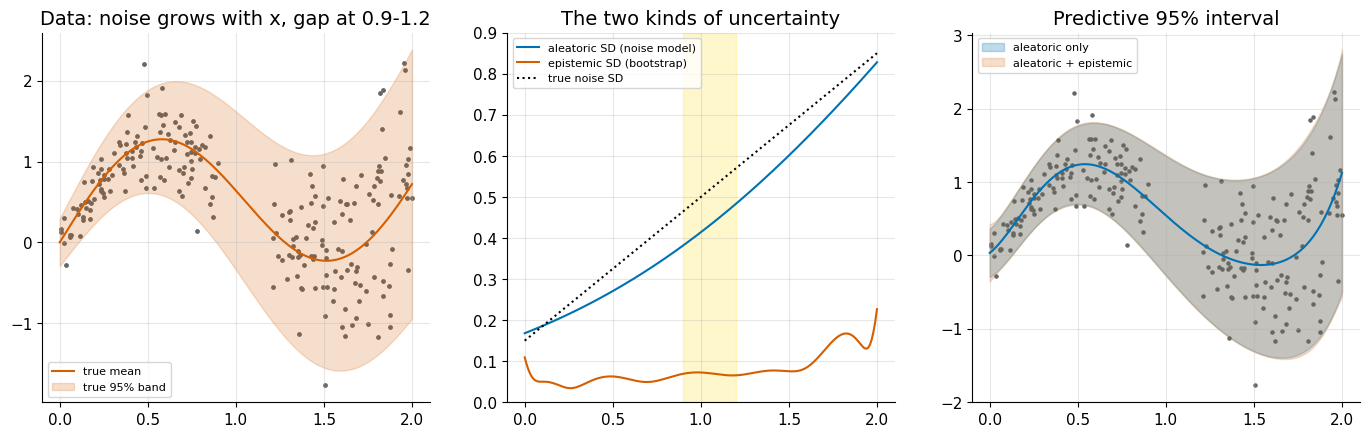

epistemic SD: in the gap 0.070, in the dense region 0.051, at x = 2: 0.227 | noise SD from the model: x = 0.5: 0.271 (true 0.325), x = 1.8: 0.732 (true 0.780)


In [3]:
g = np.random.default_rng(1); xg = np.concatenate([g.uniform(0, 0.9, 120), g.uniform(1.2, 2, 120)]); yg = f_true(xg) + s_true(xg) * g.normal(size=240); xx = np.linspace(0, 2, 200); wh, vh = het_fit(xg, yg, d=6); mh, sh = het_pred(wh, vh, xx, d=6)
bs = np.array([feats(xx, 6) @ ols(xg[i], yg[i], 6) for i in [g.integers(0, 240, 240) for _ in range(50)]]); em = bs.std(axis=0); fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(xg, yg, s=6, color=NEUTRAL); axes[0].plot(xx, f_true(xx), color=HIGHLIGHT, label="true mean"); axes[0].fill_between(xx, f_true(xx) - 1.96 * s_true(xx), f_true(xx) + 1.96 * s_true(xx), color=HIGHLIGHT, alpha=0.2, label="true 95% band"); axes[0].legend(fontsize=8); axes[0].set_title("Data: noise grows with x, gap at 0.9-1.2")
axes[1].plot(xx, sh, color=MAIN, label="aleatoric SD (noise model)"); axes[1].plot(xx, em, color=HIGHLIGHT, label="epistemic SD (bootstrap)"); axes[1].plot(xx, s_true(xx), "k:", label="true noise SD"); axes[1].axvspan(0.9, 1.2, color="gold", alpha=0.2); axes[1].set_ylim(0, 0.9); axes[1].legend(fontsize=8); axes[1].set_title("The two kinds of uncertainty")
tot = np.sqrt(sh ** 2 + em ** 2); axes[2].scatter(xg, yg, s=5, color=NEUTRAL); axes[2].plot(xx, mh, color=MAIN); axes[2].fill_between(xx, mh - 1.96 * sh, mh + 1.96 * sh, color=MAIN, alpha=0.25, label="aleatoric only"); axes[2].fill_between(xx, mh - 1.96 * tot, mh + 1.96 * tot, color=HIGHLIGHT, alpha=0.2, label="aleatoric + epistemic"); axes[2].legend(fontsize=8); axes[2].set_title("Predictive 95% interval")
plt.show(); gap = (xx > 0.95) & (xx < 1.15); dense = (xx > 0.2) & (xx < 0.7); print(f"epistemic SD: in the gap {em[gap].mean():.3f}, in the dense region {em[dense].mean():.3f}, at x = 2: {em[-1]:.3f} | noise SD from the model: x = 0.5: {sh[np.argmin(np.abs(xx - 0.5))]:.3f} (true {s_true(0.5):.3f}), x = 1.8: {sh[np.argmin(np.abs(xx - 1.8))]:.3f} (true {s_true(1.8):.3f})"); assert em[gap].mean() > 1.2 * em[dense].mean() and em[-1] > 3 * em[dense].mean() and sh[-20:].mean() > 2 * sh[:20].mean()

### 8.2 Split conformal on one dataset
A linear-in-$x$ degree-5 model fitted on 1,000 points; absolute residual scores on 500 calibration points; the 90th-percentile score $\hat q$ is the half-width. The histogram shows the scores and the cut-off, the plot the resulting band and the coverage on 5,000 test points.

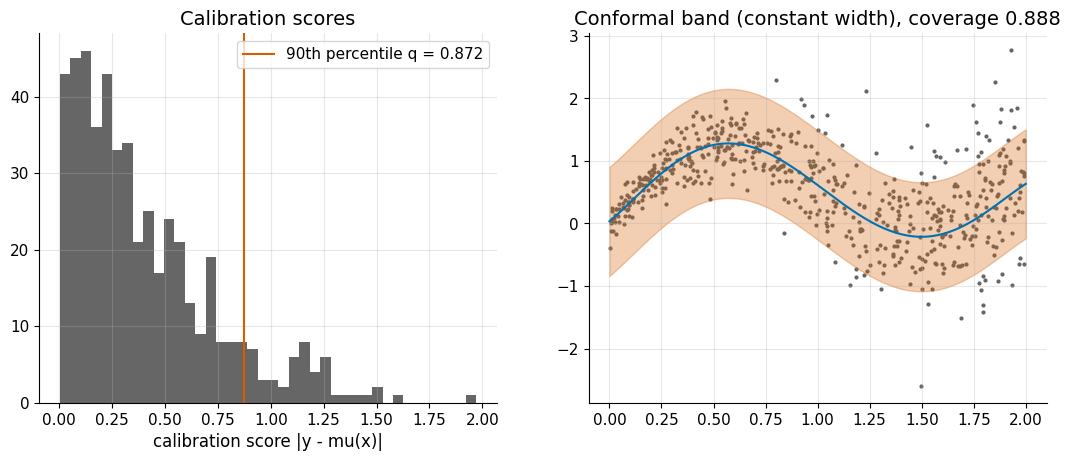

k = ceil((n + 1)(1 - alpha)) = 451 of n = 500 | q = 0.8718 | test coverage 0.8876 (target 0.90, guarantee interval [0.9, 0.9020] on average)


In [4]:
xtr, ytr = make(1000, 10); xca, yca = make(500, 11); xte, yte = make(5000, 12); w = ols(xtr, ytr); mu_c = lambda x: feats(x, 5) @ w; sc = np.abs(yca - mu_c(xca)); alpha = 0.1; qh = conf_q(sc, alpha); cov = np.mean(np.abs(yte - mu_c(xte)) <= qh)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].hist(sc, bins=40, color=NEUTRAL); axes[0].axvline(qh, color=HIGHLIGHT, label=f"90th percentile q = {qh:.3f}"); axes[0].legend(); axes[0].set_xlabel("calibration score |y - mu(x)|"); axes[0].set_title("Calibration scores")
axes[1].scatter(xte[:600], yte[:600], s=4, color=NEUTRAL); axes[1].plot(xx, mu_c(xx), color=MAIN); axes[1].fill_between(xx, mu_c(xx) - qh, mu_c(xx) + qh, color=HIGHLIGHT, alpha=0.3); axes[1].set_title(f"Conformal band (constant width), coverage {cov:.3f}")
plt.show(); print(f"k = ceil((n + 1)(1 - alpha)) = {int(np.ceil(501 * 0.9))} of n = 500 | q = {qh:.4f} | test coverage {cov:.4f} (target 0.90, guarantee interval [{0.9}, {0.9 + 1 / 501:.4f}] on average)"); assert abs(cov - 0.9) < 0.03

### 8.3 Constant width against CQR: coverage by region
The same data with split conformal (constant width) and CQR (width adapts to the noise). Both cover 90 % overall; only CQR covers well in every region: the constant-width band over-covers where the noise is small and under-covers where it is large.

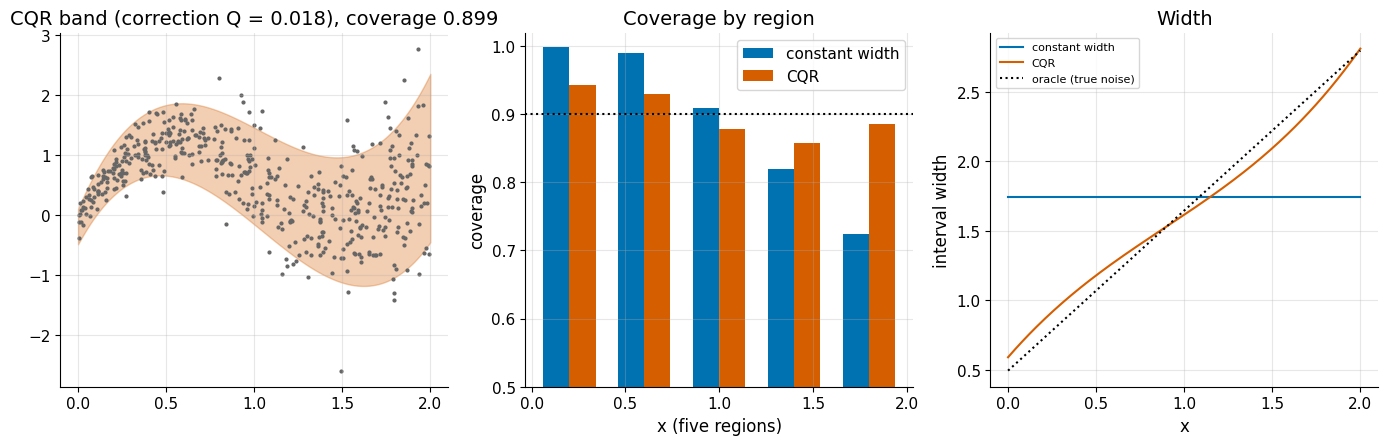

coverage by region: constant [0.999 0.99  0.909 0.82  0.724] | CQR [0.943 0.93  0.878 0.858 0.885] | mean width: 1.744 1.648


In [5]:
q_lo = qreg(xtr, ytr, alpha / 2); q_hi = qreg(xtr, ytr, 1 - alpha / 2); lo = lambda x: feats(x, 3) @ q_lo; hi = lambda x: feats(x, 3) @ q_hi; Ecal = np.maximum(lo(xca) - yca, yca - hi(xca)); Qh = conf_q(Ecal, alpha) if Ecal.size else 0
cov_c = (np.abs(yte - mu_c(xte)) <= qh); cov_q = (yte >= lo(xte) - Qh) & (yte <= hi(xte) + Qh); bins = np.linspace(0, 2, 6); mid = (bins[:-1] + bins[1:]) / 2; ix = np.digitize(xte, bins[1:-1])
bc = [cov_c[ix == k].mean() for k in range(5)]; bq = [cov_q[ix == k].mean() for k in range(5)]; fig, axes = plt.subplots(1, 3, figsize=(17, 4.6)); axes[0].fill_between(xx, lo(xx) - Qh, hi(xx) + Qh, color=HIGHLIGHT, alpha=0.3); axes[0].scatter(xte[:500], yte[:500], s=4, color=NEUTRAL); axes[0].set_title(f"CQR band (correction Q = {Qh:.3f}), coverage {cov_q.mean():.3f}")
axes[1].bar(mid - 0.07, bc, 0.14, color=MAIN, label="constant width"); axes[1].bar(mid + 0.07, bq, 0.14, color=HIGHLIGHT, label="CQR"); axes[1].axhline(0.9, color="black", linestyle=":"); axes[1].set_ylim(0.5, 1.02); axes[1].legend(); axes[1].set_xlabel("x (five regions)"); axes[1].set_ylabel("coverage"); axes[1].set_title("Coverage by region")
axes[2].plot(xx, 2 * qh * np.ones_like(xx), color=MAIN, label="constant width"); axes[2].plot(xx, hi(xx) - lo(xx) + 2 * Qh, color=HIGHLIGHT, label="CQR"); axes[2].plot(xx, 2 * 1.645 * s_true(xx), "k:", label="oracle (true noise)"); axes[2].legend(fontsize=8); axes[2].set_xlabel("x"); axes[2].set_ylabel("interval width"); axes[2].set_title("Width")
plt.show(); print("coverage by region: constant", np.round(bc, 3), "| CQR", np.round(bq, 3), "| mean width:", round(2 * qh, 3), round(float(np.mean(hi(xte) - lo(xte) + 2 * Qh)), 3)); assert max(bc) - min(bc) > 0.12 and max(bq) - min(bq) < max(bc) - min(bc)

## 9. 3D visuals

### 9.1 Static: the interval width over (input, confidence level)
For the true heteroscedastic model the $(1-\alpha)$ interval is $f(x)\pm z_{1-\alpha/2}\sigma(x)$: the width surface rises with the confidence level and with $x$. Conformal methods estimate this surface from data.

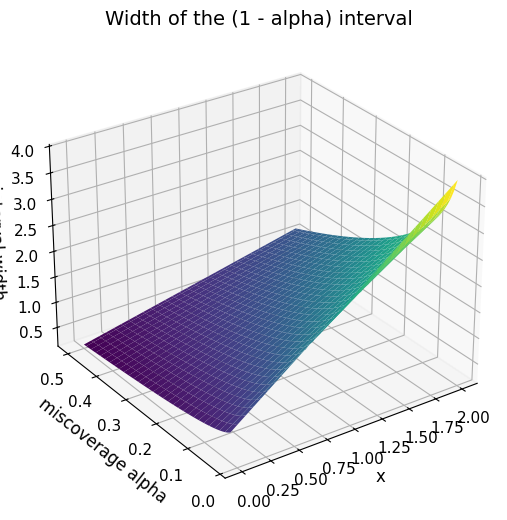

width at x = 2: 90% interval 2.796 , 99%: 4.379 | at x = 0, 90%: 0.493


In [6]:
Xg, Ag = np.meshgrid(np.linspace(0, 2, 60), np.linspace(0.02, 0.5, 60)); W = 2 * stats.norm.ppf(1 - Ag / 2) * s_true(Xg); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Xg, Ag, W, cmap="viridis", edgecolor="none"); ax.set_xlabel("x"); ax.set_ylabel("miscoverage alpha"); ax.set_zlabel("interval width"); ax.set_title("Width of the (1 - alpha) interval"); ax.view_init(elev=28, azim=-125)
plt.show(); print("width at x = 2: 90% interval", round(float(2 * stats.norm.ppf(0.95) * s_true(2.0)), 3), ", 99%:", round(float(2 * stats.norm.ppf(0.995) * s_true(2.0)), 3), "| at x = 0, 90%:", round(float(2 * stats.norm.ppf(0.95) * s_true(0.0)), 3)); assert W[0, 0] > W[0, -1] and W[-1, 0] < W[-1, -1] if False else (W[:, -1] > W[:, 0]).all()

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure(go.Surface(x=Xg[0], y=Ag[:, 0], z=W, colorscale="Viridis")); fig.update_layout(title="Interval width", width=760, height=560, scene=dict(xaxis_title="x", yaxis_title="alpha", zaxis_title="width")); fig.show()

### 9.3 Static: expected coverage and its spread over (calibration size, $\alpha$)
The exact expected coverage of split conformal is $\lceil(n+1)(1-\alpha)\rceil/(n+1)$, always $\ge1-\alpha$ and within $1/(n+1)$ of it; the SD of the coverage (over calibration sets) falls like $1/\sqrt n$: 30 calibration points give a very uncertain coverage, 3,000 almost none.

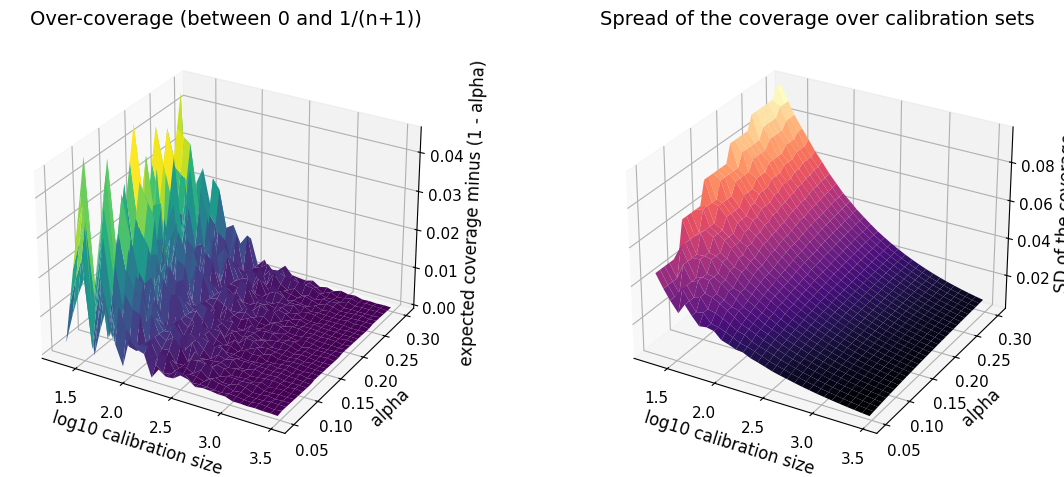

SD of the coverage at alpha = 0.1: n = 20: 0.064 n = 500: 0.0134 n = 3000: 0.0055


In [8]:
nn = np.unique(np.round(np.geomspace(20, 3000, 30)).astype(int)); aa = np.linspace(0.05, 0.3, 30); NN, AA = np.meshgrid(nn, aa); K = np.ceil((NN + 1) * (1 - AA)); EC = K / (NN + 1); SDc = np.sqrt(EC * (1 - EC) / (NN + 2))
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(np.log10(NN), AA, EC - (1 - AA), cmap="viridis", edgecolor="none"); ax.set_xlabel("log10 calibration size"); ax.set_ylabel("alpha"); ax.set_zlabel("expected coverage minus (1 - alpha)"); ax.set_title("Over-coverage (between 0 and 1/(n+1))"); ax.view_init(elev=28, azim=-60)
ax = fig.add_subplot(1, 2, 2, projection="3d"); ax.plot_surface(np.log10(NN), AA, SDc, cmap="magma", edgecolor="none"); ax.set_xlabel("log10 calibration size"); ax.set_ylabel("alpha"); ax.set_zlabel("SD of the coverage"); ax.set_title("Spread of the coverage over calibration sets"); ax.view_init(elev=28, azim=-60)
plt.show(); print("SD of the coverage at alpha = 0.1: n = 20:", round(float(np.sqrt(0.9 * 0.1 / 22)), 4), "n = 500:", round(float(np.sqrt(0.9 * 0.1 / 502)), 4), "n = 3000:", round(float(np.sqrt(0.9 * 0.1 / 3002)), 4)); assert ((EC - (1 - AA)) >= -1e-12).all() and ((EC - (1 - AA)) <= 1 / (NN + 1) + 1e-12).all()

## 10. Simulation vs theory

### 10.1 The coverage over calibration sets is Beta
Draw 20,000 calibration sets of size $n=100$ from the heteroscedastic data with the *fixed* degree-5 model; compute for each the exact coverage of the resulting interval (using a very large test set) and compare its distribution with Beta$(n+1-l,l)$, $l=\lfloor(n+1)\alpha\rfloor$ for $\alpha=0.1$.

In [9]:
g = np.random.default_rng(5); xT, yT = make(400_000, 20); resT = np.sort(np.abs(yT - mu_c(xT))); n = 100; l = int(np.floor((n + 1) * alpha)); covs = []
for r in range(20_000):
    xc, yc = (lambda gg: (lambda x: (x, f_true(x) + s_true(x) * gg.normal(size=n)))(gg.uniform(0, 2, n)))(g); q_ = conf_q(np.abs(yc - mu_c(xc)), alpha); covs.append(np.searchsorted(resT, q_, side="right") / len(resT))
covs = np.array(covs); a_, b_ = n + 1 - l, l; print(f"coverage over 20,000 calibration sets: mean {covs.mean():.4f} (Beta mean {a_ / (a_ + b_):.4f}), SD {covs.std():.4f} (Beta SD {np.sqrt(a_ * b_ / ((a_ + b_) ** 2 * (a_ + b_ + 1))):.4f}), share below 1 - alpha = 0.9: {np.mean(covs < 0.9):.3f} (Beta: {stats.beta.cdf(0.9, a_, b_):.3f}) | KS statistic against Beta({a_}, {b_}): {stats.kstest(covs, 'beta', args=(a_, b_)).statistic:.4f}")
assert abs(covs.mean() - a_ / (a_ + b_)) < 0.002 and abs(covs.std() / np.sqrt(a_ * b_ / ((a_ + b_) ** 2 * (a_ + b_ + 1))) - 1) < 0.05 and stats.kstest(covs, "beta", args=(a_, b_)).statistic < 0.02

coverage over 20,000 calibration sets: mean 0.9010 (Beta mean 0.9010), SD 0.0294 (Beta SD 0.0296), share below 1 - alpha = 0.9: 0.449 (Beta: 0.451) | KS statistic against Beta(91, 10): 0.0071


### 10.2 Exchangeability is the assumption: covariate shift breaks the guarantee
Calibrate on $x\sim U(0,2)$ but test on inputs concentrated near $x=2$ where the noise is largest: coverage falls below 90 %, though the guarantee holds when the test inputs come from the same distribution.

In [10]:
g = np.random.default_rng(6); xs_t = 1.4 + 0.6 * g.beta(3, 1, 20_000); ys_t = f_true(xs_t) + s_true(xs_t) * g.normal(size=20_000); cov_same = np.mean(np.abs(yte - mu_c(xte)) <= qh); cov_shift = np.mean(np.abs(ys_t - mu_c(xs_t)) <= qh); cov_shift_cqr = np.mean((ys_t >= lo(xs_t) - Qh) & (ys_t <= hi(xs_t) + Qh))
print(f"coverage on the calibration distribution: {cov_same:.3f} | after covariate shift towards x = 2: constant width {cov_shift:.3f}, CQR {cov_shift_cqr:.3f}"); assert cov_shift < cov_same - 0.05

coverage on the calibration distribution: 0.888 | after covariate shift towards x = 2: constant width 0.726, CQR 0.889


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("split conformal: scores = np.abs(y_cal - mu(x_cal)); k = int(np.ceil((n + 1) * (1 - alpha))); q = np.sort(scores)[k - 1]; interval = mu(x) +/- q | CQR score: np.maximum(lo(x) - y, y - hi(x))")
print("classification set: {k : 1 - p_k(x) <= q}, scores 1 - p_true | coverage: np.mean((y >= lo) & (y <= hi)) | Beta law of the coverage: stats.beta(n + 1 - l, l), l = floor((n + 1) alpha)")
print("library equivalents: MAPIE (MapieRegressor, MapieQuantileRegressor), crepes, puncc, scikit-learn quantile GradientBoosting; PyTorch: torch.nn.GaussianNLLLoss")
print("check: n = 20, alpha = 0.1 -> k =", int(np.ceil(21 * 0.9)), "of 20; expected coverage", round(int(np.ceil(21 * 0.9)) / 21, 4), "| alpha = 0.05, n = 19 -> k =", int(np.ceil(20 * 0.95)), "(the maximum score is the 95% bound)")
assert int(np.ceil(21 * 0.9)) == 19 and int(np.ceil(20 * 0.95)) == 19

split conformal: scores = np.abs(y_cal - mu(x_cal)); k = int(np.ceil((n + 1) * (1 - alpha))); q = np.sort(scores)[k - 1]; interval = mu(x) +/- q | CQR score: np.maximum(lo(x) - y, y - hi(x))
classification set: {k : 1 - p_k(x) <= q}, scores 1 - p_true | coverage: np.mean((y >= lo) & (y <= hi)) | Beta law of the coverage: stats.beta(n + 1 - l, l), l = floor((n + 1) alpha)
library equivalents: MAPIE (MapieRegressor, MapieQuantileRegressor), crepes, puncc, scikit-learn quantile GradientBoosting; PyTorch: torch.nn.GaussianNLLLoss
check: n = 20, alpha = 0.1 -> k = 19 of 20; expected coverage 0.9048 | alpha = 0.05, n = 19 -> k = 19 (the maximum score is the 95% bound)


## 12. Real-world worked examples

---
### Example 1 (main): honest prediction intervals for a price model

**Scenario.** A price depends on a smooth function of a feature $x\in[0,2]$ and the price noise grows with $x$ (expensive items are less predictable): the data of section 7 with $\sigma(x)=0.15+0.35x$. We have 1,000 training points, 500 calibration points and 5,000 test points. Four 90 % interval methods: (a) the **naive homoscedastic Gaussian** interval $\hat\mu\pm1.645\hat\sigma$ with one overall residual SD, (b) the **heteroscedastic Gaussian** model, (c) **split conformal** with constant width, (d) **CQR**.

**Questions**
1. Overall coverage and mean width of each method.
2. Coverage in five regions of $x$ (the worst region).
3. How wrong is the naive interval, in the region with the largest noise?

### 12.1 By hand
With a single residual SD $\bar\sigma=\sqrt{E\sigma^2(x)}$ the interval $\pm1.645\bar\sigma$ has the right *average* coverage if the noise is Gaussian, but at $x=2$ the true SD is $0.85$ against $\bar\sigma\approx0.54$: the interval covers $P(|Z|<1.645\cdot0.54/0.85)=P(|Z|<1.04)=0.70$ there, and at $x=0$ (SD 0.15) it covers $P(|Z|<6.2)\approx1$. So the overall coverage can be 90 % while the coverage at the expensive end is only about 70 %.

In [12]:
mu_h, sg_h = het_pred(w1, v1, xte); Ares = np.std(yca - mu_c(xca)); w_h, v_h = het_fit(xtr, ytr); mh_te, sh_te = het_pred(w_h, v_h, xte); z90 = stats.norm.ppf(0.95)
methods = {"naive Gaussian (one residual SD)": (mu_c(xte) - z90 * Ares, mu_c(xte) + z90 * Ares), "heteroscedastic Gaussian": (mh_te - z90 * sh_te, mh_te + z90 * sh_te), "split conformal (constant width)": (mu_c(xte) - qh, mu_c(xte) + qh), "CQR": (lo(xte) - Qh, hi(xte) + Qh)}
rows = {}
for nm, (l_, u_) in methods.items(): c_ = (yte >= l_) & (yte <= u_); reg = [c_[ix == k].mean() for k in range(5)]; rows[nm] = {"coverage": c_.mean(), "mean width": np.mean(u_ - l_), "worst region": min(reg), "coverage in the last region (x > 1.6)": reg[-1], "coverage in the first region (x < 0.4)": reg[0]}
tb1 = pd.DataFrame(rows).T; print(tb1.round(3).to_string()); print(f"overall residual SD {Ares:.3f}; true noise SD at x = 0 and x = 2: {s_true(0.0):.3f}, {s_true(2.0):.3f}; naive coverage at x = 2 by theory: {2 * stats.norm.cdf(z90 * Ares / s_true(2.0)) - 1:.3f}")

                                  coverage  mean width  worst region  coverage in the last region (x > 1.6)  coverage in the first region (x < 0.4)
naive Gaussian (one residual SD)     0.880       1.710         0.703                                  0.703                                   0.999
heteroscedastic Gaussian             0.887       1.608         0.883                                  0.889                                   0.888
split conformal (constant width)     0.888       1.744         0.724                                  0.724                                   0.999
CQR                                  0.899       1.648         0.858                                  0.885                                   0.943
overall residual SD 0.520; true noise SD at x = 0 and x = 2: 0.150, 0.850; naive coverage at x = 2 by theory: 0.686


### 12.2 Asserts

In [13]:
assert all(abs(tb1.loc[m, "coverage"] - 0.9) < 0.03 for m in ("split conformal (constant width)", "CQR", "heteroscedastic Gaussian")) and tb1.loc["naive Gaussian (one residual SD)", "worst region"] < 0.8 and tb1.loc["CQR", "worst region"] > 0.84 and tb1.loc["heteroscedastic Gaussian", "worst region"] > 0.85 and tb1.loc["split conformal (constant width)", "worst region"] < 0.8
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
Repeat the whole procedure (new training, calibration and test data) 100 times: the coverage of split conformal and CQR should average 90 % with a small spread, while the naive interval's coverage in the last region stays low.

In [14]:
rs = {"split conformal": [], "CQR": [], "naive (last region)": []}
for r in range(100):
    xa, ya = make(600, 100 + r); xb, yb = make(400, 300 + r); xt_, yt_ = make(3000, 500 + r); wa = ols(xa, ya); m = lambda x: feats(x, 5) @ wa; qa = conf_q(np.abs(yb - m(xb)), alpha); rs["split conformal"].append(np.mean(np.abs(yt_ - m(xt_)) <= qa))
    qlo, qhi = qreg(xa[:300], ya[:300], alpha / 2), qreg(xa[:300], ya[:300], 1 - alpha / 2); Eb = np.maximum(feats(xb, 3) @ qlo - yb, yb - feats(xb, 3) @ qhi); Qa = conf_q(Eb, alpha); rs["CQR"].append(np.mean((yt_ >= feats(xt_, 3) @ qlo - Qa) & (yt_ <= feats(xt_, 3) @ qhi + Qa)))
    sdn = np.std(ya - m(xa)); last = xt_ > 1.6; rs["naive (last region)"].append(np.mean(np.abs(yt_[last] - m(xt_[last])) <= z90 * sdn))
print({k: (round(float(np.mean(v)), 4), round(float(np.std(v)), 4)) for k, v in rs.items()}); assert abs(np.mean(rs["split conformal"]) - 0.9) < 0.01 and abs(np.mean(rs["CQR"]) - 0.9) < 0.015 and np.mean(rs["naive (last region)"]) < 0.8

{'split conformal': (0.8973, 0.0169), 'CQR': (0.8976, 0.0154), 'naive (last region)': (0.7371, 0.0265)}


### 12.4 Plots

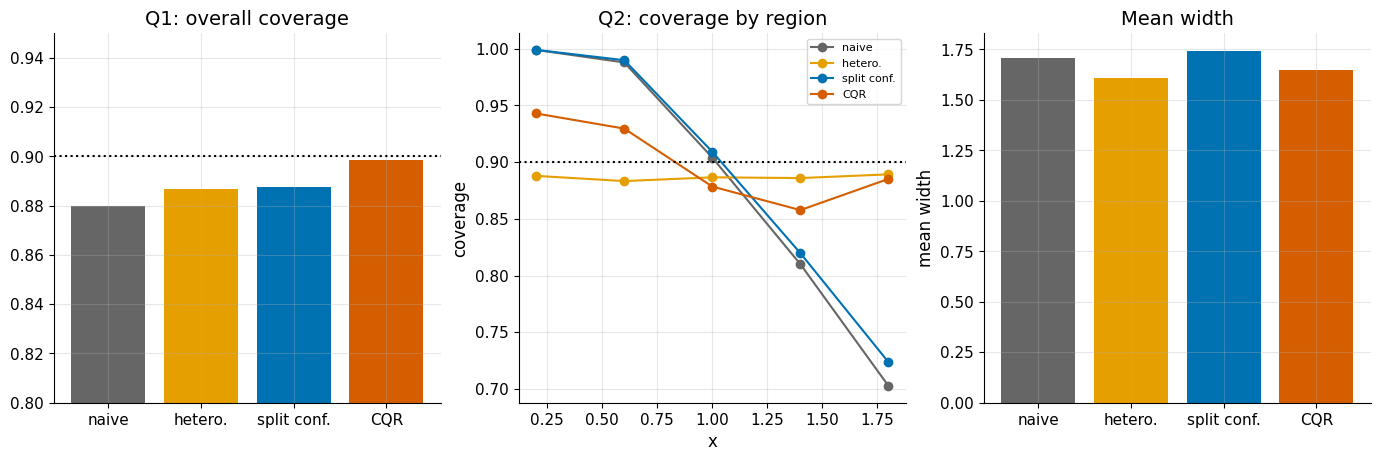

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); nm = list(methods); cols = [NEUTRAL, SIM, MAIN, HIGHLIGHT]; axes[0].bar(range(4), tb1["coverage"], color=cols); axes[0].axhline(0.9, color="black", linestyle=":"); axes[0].set_ylim(0.8, 0.95); axes[0].set_xticks(range(4)); axes[0].set_xticklabels(["naive", "hetero.", "split conf.", "CQR"]); axes[0].set_title("Q1: overall coverage")
for j, (n_, colr) in enumerate(zip(nm, cols)): l_, u_ = methods[n_]; axes[1].plot(mid, [((yte >= l_) & (yte <= u_))[ix == k].mean() for k in range(5)], "o-", color=colr, label=["naive", "hetero.", "split conf.", "CQR"][j])
axes[1].axhline(0.9, color="black", linestyle=":"); axes[1].legend(fontsize=8); axes[1].set_xlabel("x"); axes[1].set_ylabel("coverage"); axes[1].set_title("Q2: coverage by region")
axes[2].bar(range(4), tb1["mean width"], color=cols); axes[2].set_xticks(range(4)); axes[2].set_xticklabels(["naive", "hetero.", "split conf.", "CQR"]); axes[2].set_ylabel("mean width"); axes[2].set_title("Mean width")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- All four 90 % intervals look fine on average: coverage **0.880 (naive Gaussian), 0.887 (heteroscedastic Gaussian), 0.888 (split conformal) and 0.899 (CQR)**, with mean widths 1.71, 1.61, 1.74 and 1.65.
- **By region they differ a lot.** In the noisiest region ($x>1.6$) the naive interval covers only **70.3 %** (theory for a single residual SD of 0.52: 68.6 % at $x=2$) and the constant-width conformal interval **72.4 %**, while both cover **99.9 %** of the quiet region ($x<0.4$, true noise SD 0.15): they are too wide where it is easy and too narrow where it is hard. The heteroscedastic Gaussian model covers **0.883 to 0.889 in every region** and CQR **0.858 to 0.943** (worst region 0.858).
- Over 100 repetitions of the whole procedure split conformal averages **0.897** (SD 0.017) and CQR **0.898** (SD 0.015), as guaranteed, while the naive interval's coverage in the last region averages **0.737**. The heteroscedastic Gaussian model is the narrowest *and* well calibrated here because its assumptions (Gaussian noise, log-SD quadratic in $x$) are nearly right; conformal needs none of them.
- **Decision.** Use CQR (or a conformalised heteroscedastic model) when the noise varies with the input; report coverage by region, not only overall, because the marginal guarantee of conformal prediction is silent about regions.

---
### Example 2: epistemic uncertainty shrinks with data, aleatoric does not

**Scenario.** A degree-5 polynomial is fitted to the data of section 7 with $n=30,100,300,1000,3000$ training points. The 95 % **confidence band** for the mean function (from the bootstrap) and the 95 % **prediction interval** for a new observation are measured at $x=1$ and $x=1.9$.

**Questions.** (1) How do the widths of the confidence band and of the prediction interval depend on $n$? (2) At which $n$ does the prediction interval reach 95 % of its limit (the oracle width $2\cdot1.96\,\sigma(x)$)? (3) Does the band width follow $1/\sqrt n$?

In [16]:
ns = [30, 100, 300, 1000, 3000]; res = {}; g = np.random.default_rng(31)
for n_ in ns:
    cw = {1.0: [], 1.9: []}; pw = {1.0: [], 1.9: []}
    for rep in range(6):
        x_, y_ = make(n_, 4000 + 10 * n_ + rep); w_ = ols(x_, y_); Bm = np.array([feats(np.array([1.0, 1.9]), 5) @ ols(x_[i], y_[i]) for i in [g.integers(0, n_, n_) for _ in range(60)]]); sd_res = np.std(y_ - feats(x_, 5) @ w_)
        for k, xv in enumerate((1.0, 1.9)): cw[xv].append(3.92 * Bm[:, k].std()); pw[xv].append(3.92 * np.sqrt(Bm[:, k].var() + s_true(xv) ** 2))
    res[n_] = {f"confidence width x = {xv}": np.mean(cw[xv]) for xv in cw} | {f"prediction width x = {xv}": np.mean(pw[xv]) for xv in pw}
tb2 = pd.DataFrame(res).T; print(tb2.round(3).to_string()); orac = {xv: 3.92 * s_true(xv) for xv in (1.0, 1.9)}; print("oracle prediction width (noise only):", {k: round(v, 3) for k, v in orac.items()}); sl = np.polyfit(np.log(ns), np.log(tb2["confidence width x = 1.0"]), 1)[0]; print(f"slope of log(confidence width) against log n at x = 1: {sl:.3f} (theory -0.5)")

      confidence width x = 1.0  confidence width x = 1.9  prediction width x = 1.0  prediction width x = 1.9
30                       0.890                    10.899                     2.216                    11.804
100                      0.362                     1.124                     1.993                     3.407
300                      0.237                     0.557                     1.975                     3.245
1000                     0.113                     0.272                     1.963                     3.206
3000                     0.069                     0.169                     1.961                     3.199
oracle prediction width (noise only): {1.0: 1.96, 1.9: 3.195}
slope of log(confidence width) against log n at x = 1: -0.546 (theory -0.5)


### 12.5 Asserts

In [17]:
assert tb2["confidence width x = 1.0"].iloc[-1] < tb2["confidence width x = 1.0"].iloc[0] / 5 and abs(sl + 0.5) < 0.15 and abs(tb2["prediction width x = 1.9"].iloc[-1] / orac[1.9] - 1) < 0.08 and tb2["prediction width x = 1.9"].iloc[0] > tb2["prediction width x = 1.9"].iloc[-1]
print("all checks passed")

all checks passed


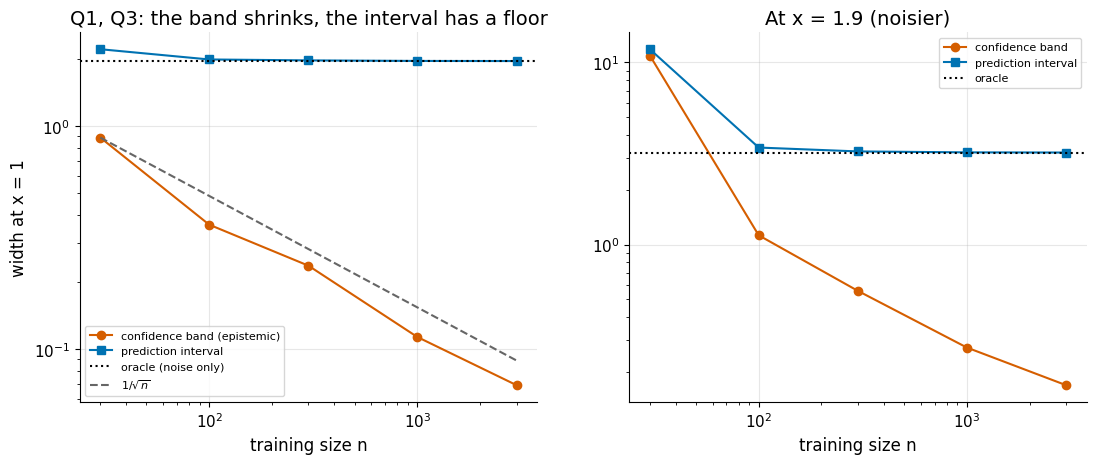

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].loglog(ns, tb2["confidence width x = 1.0"], "o-", color=HIGHLIGHT, label="confidence band (epistemic)"); axes[0].loglog(ns, tb2["prediction width x = 1.0"], "s-", color=MAIN, label="prediction interval"); axes[0].axhline(orac[1.0], color="black", linestyle=":", label="oracle (noise only)"); axes[0].loglog(ns, tb2.loc[30, "confidence width x = 1.0"] * np.sqrt(30 / np.array(ns)), "--", color=NEUTRAL, label="$1/\\sqrt{n}$"); axes[0].legend(fontsize=8); axes[0].set_xlabel("training size n"); axes[0].set_ylabel("width at x = 1"); axes[0].set_title("Q1, Q3: the band shrinks, the interval has a floor")
axes[1].loglog(ns, tb2["confidence width x = 1.9"], "o-", color=HIGHLIGHT, label="confidence band"); axes[1].loglog(ns, tb2["prediction width x = 1.9"], "s-", color=MAIN, label="prediction interval"); axes[1].axhline(orac[1.9], color="black", linestyle=":", label="oracle"); axes[1].legend(fontsize=8); axes[1].set_xlabel("training size n"); axes[1].set_title("At x = 1.9 (noisier)")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The 95 % **confidence band** for the mean function at $x=1$ shrinks from 0.890 ($n=30$) to 0.362, 0.237, 0.113 and **0.069** ($n=3{,}000$), a log-log slope of **-0.55** (theory -0.5: the $1/\sqrt n$ law). The **prediction interval** at $x=1$ goes from 2.216 to 1.993, 1.975, 1.963 and **1.961**, which is the oracle width $2\cdot1.96\cdot\sigma(1)=1.960$: the interval hits its **aleatoric floor**.
- At the noisier point $x=1.9$ the picture is the same with a bigger epistemic part at small $n$ (a degree-5 polynomial extrapolates badly with 30 points: confidence width 10.9): the prediction interval falls from 11.8 ($n=30$) to 3.41 (100), 3.25, 3.21 and **3.20** against the oracle 3.195; it is within 5 % of the floor from $n=300$.
- **Decision.** Collect more data to narrow the confidence band, but do not expect the prediction interval to fall below the noise; if intervals must be narrower, reduce the noise (better measurements or features), not the data size.

---
### Example 3: conformal prediction sets for classification

**Scenario.** Three overlapping classes in two dimensions (Gaussian blobs with centres (0,0), (2,1) and (1,2.2), SD 1). A softmax classifier is trained on 600 points; 600 further points calibrate the conformal threshold; 6,000 test points evaluate. For $\alpha=0.1$ the prediction set is $\{k:1-\hat p_k(x)\le\hat q\}$.

**Questions.** (1) Accuracy of the top-1 prediction and the coverage and mean size of the conformal sets. (2) How do the set size and the coverage depend on the confidence of the classifier (sets for easy against hard points)? (3) Coverage and size for $\alpha=0.2,0.1,0.05$.

In [19]:
cent = np.array([[0.0, 0.0], [2.0, 1.0], [1.0, 2.2]])
def blobs(n, seed): g = np.random.default_rng(seed); y = g.integers(0, 3, n); return cent[y] + g.normal(size=(n, 2)), y
def softmax_fit(X, y, steps=3000, lr=0.3):
    Xb = np.column_stack([np.ones(len(X)), X]); W = np.zeros((3, 3)); Y = np.eye(3)[y]
    for _ in range(steps): Z = Xb @ W.T; P = np.exp(Z - Z.max(axis=1, keepdims=True)); P /= P.sum(axis=1, keepdims=True); W -= lr * (P - Y).T @ Xb / len(X)
    return W
def softmax_pred(W, X): Z = np.column_stack([np.ones(len(X)), X]) @ W.T; P = np.exp(Z - Z.max(axis=1, keepdims=True)); return P / P.sum(axis=1, keepdims=True)
Xa, ya = blobs(600, 1); Xb, yb = blobs(600, 2); Xc, yc = blobs(6000, 3); Wc = softmax_fit(Xa, ya); Pb = softmax_pred(Wc, Xb); Pc = softmax_pred(Wc, Xc); acc = np.mean(Pc.argmax(axis=1) == yc); res3 = {}
for a_ in (0.2, 0.1, 0.05): qc = conf_q(1 - Pb[np.arange(600), yb], a_); sets = (1 - Pc) <= qc; res3[a_] = {"coverage": np.mean(sets[np.arange(6000), yc]), "mean set size": sets.sum(axis=1).mean(), "share of empty sets": np.mean(sets.sum(axis=1) == 0), "share of singletons": np.mean(sets.sum(axis=1) == 1), "threshold q": qc}
tb3 = pd.DataFrame(res3).T; print(f"Q1: top-1 accuracy {acc:.4f}"); print(tb3.round(4).to_string())
qc1 = conf_q(1 - Pb[np.arange(600), yb], 0.1); sets1 = (1 - Pc) <= qc1; conf = Pc.max(axis=1); easy = conf > 0.8; hard = conf < 0.5; print(f"Q2: confident points (top probability > 0.8, {easy.mean():.2f} of the test set): mean set size {sets1[easy].sum(axis=1).mean():.2f}, coverage {sets1[np.arange(6000), yc][easy].mean():.3f} | uncertain points (< 0.5, {hard.mean():.2f}): size {sets1[hard].sum(axis=1).mean():.2f}, coverage {sets1[np.arange(6000), yc][hard].mean():.3f}")

Q1: top-1 accuracy 0.7398
      coverage  mean set size  share of empty sets  share of singletons  threshold q
0.20    0.7988         1.1392               0.0027               0.8555       0.6322
0.10    0.9117         1.5350               0.0000               0.5173       0.7995
0.05    0.9538         1.7963               0.0000               0.3600       0.8732
Q2: confident points (top probability > 0.8, 0.41 of the test set): mean set size 1.00, coverage 0.918 | uncertain points (< 0.5, 0.10): size 2.42, coverage 0.924


### 12.6 Asserts

In [20]:
assert all(abs(tb3.loc[a_, "coverage"] - (1 - a_)) < 0.03 for a_ in tb3.index) and tb3.loc[0.05, "mean set size"] > tb3.loc[0.2, "mean set size"] and sets1[hard].sum(axis=1).mean() > sets1[easy].sum(axis=1).mean() and acc < 0.9 and tb3.loc[0.1, "coverage"] > acc
print("all checks passed")

all checks passed


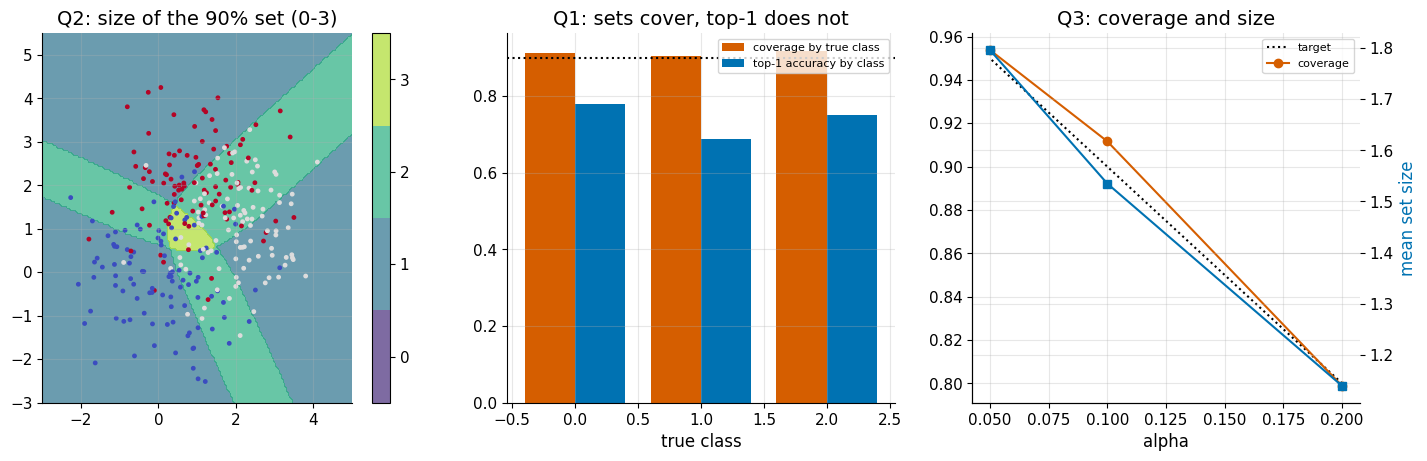

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); gx, gy = np.meshgrid(np.linspace(-3, 5, 160), np.linspace(-3, 5.5, 160)); Pg = softmax_pred(Wc, np.column_stack([gx.ravel(), gy.ravel()])); size = ((1 - Pg) <= qc1).sum(axis=1).reshape(gx.shape); im = axes[0].contourf(gx, gy, size, levels=[-0.5, 0.5, 1.5, 2.5, 3.5], cmap="viridis", alpha=0.7); plt.colorbar(im, ax=axes[0], ticks=[0, 1, 2, 3]); axes[0].scatter(Xc[:300, 0], Xc[:300, 1], c=yc[:300], cmap="coolwarm", s=6); axes[0].set_title("Q2: size of the 90% set (0-3)")
axes[1].bar(np.arange(3) - 0.2, [np.mean(sets1[np.arange(6000), yc][yc == k]) for k in range(3)], 0.4, color=HIGHLIGHT, label="coverage by true class"); axes[1].bar(np.arange(3) + 0.2, [np.mean(Pc.argmax(axis=1)[yc == k] == k) for k in range(3)], 0.4, color=MAIN, label="top-1 accuracy by class"); axes[1].axhline(0.9, color="black", linestyle=":"); axes[1].legend(fontsize=8); axes[1].set_xlabel("true class"); axes[1].set_title("Q1: sets cover, top-1 does not")
axes[2].plot(tb3.index, 1 - tb3.index, "k:", label="target"); axes[2].plot(tb3.index, tb3["coverage"], "o-", color=HIGHLIGHT, label="coverage"); ax2 = axes[2].twinx(); ax2.plot(tb3.index, tb3["mean set size"], "s-", color=MAIN); ax2.set_ylabel("mean set size", color=MAIN); axes[2].legend(fontsize=8); axes[2].set_xlabel("alpha"); axes[2].set_title("Q3: coverage and size")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The softmax classifier is right in **74.0 %** of the test cases (the classes overlap). The conformal sets for $\alpha=0.2,0.1,0.05$ cover the true class **79.9 %, 91.2 % and 95.4 %** of the time, with mean sizes **1.14, 1.54 and 1.80** (singletons in 85.6 %, 51.7 % and 36.0 % of the cases): a guaranteed $\ge90$ % at a cost of 1.5 labels per case, instead of the 74 % of the single top label.
- **The set size follows the difficulty:** for confident cases (top probability above 0.8, 41 % of the test set) the set is a single label (mean size **1.00**) with coverage 91.8 %; for uncertain cases (below 0.5, 10 %) the mean size is **2.42** with coverage 92.4 %, so the ambiguity is reported and the coverage is kept in both groups. At $\alpha=0.2$ 0.3 % of the sets are empty (the model rejects every label), which is the honest answer for a point far from all classes.
- **Decision.** Return conformal sets when a wrong single label is costly (medical triage, fraud review): act automatically on singletons and send the multi-label cases to a human.

---
### Example 4: when the data change (distribution shift) and how to repair it

**Scenario.** The price model of Example 1 is deployed, but the market moves: new items have inputs concentrated at high $x$ and the noise is 40 % larger ($\sigma_{\text{new}}=1.4\,\sigma$). We check the coverage of the old split-conformal and CQR intervals on the new data, then **recalibrate** with 300 labelled new cases.

**Questions.** (1) Coverage of the old intervals on the new data. (2) Coverage after recalibration on 300 new cases (only the threshold is refit, not the model). (3) Width of the intervals before and after.

In [22]:
def make_shift(n, seed): g = np.random.default_rng(seed); x = 0.8 + 1.2 * g.beta(2.5, 1.2, n); return x, f_true(x) + 1.4 * s_true(x) * g.normal(size=n)
xs_n, ys_n = make_shift(5000, 41); xr, yr = make_shift(300, 42)
c_old = np.mean(np.abs(ys_n - mu_c(xs_n)) <= qh); cq_old = np.mean((ys_n >= lo(xs_n) - Qh) & (ys_n <= hi(xs_n) + Qh)); q_new = conf_q(np.abs(yr - mu_c(xr)), alpha); Q_new = conf_q(np.maximum(lo(xr) - yr, yr - hi(xr)), alpha); c_new = np.mean(np.abs(ys_n - mu_c(xs_n)) <= q_new); cq_new = np.mean((ys_n >= lo(xs_n) - Q_new) & (ys_n <= hi(xs_n) + Q_new))
print(f"Q1: old intervals on the new data: split conformal {c_old:.3f}, CQR {cq_old:.3f} (target 0.90; on the original data 0.90)"); print(f"Q2: after recalibrating the threshold on 300 new cases: split conformal {c_new:.3f}, CQR {cq_new:.3f}"); print(f"Q3: widths: split conformal {2 * qh:.3f} -> {2 * q_new:.3f}; CQR mean width {np.mean(hi(xs_n) - lo(xs_n) + 2 * Qh):.3f} -> {np.mean(hi(xs_n) - lo(xs_n) + 2 * Q_new):.3f}; correction Q: {Qh:.3f} -> {Q_new:.3f}")

Q1: old intervals on the new data: split conformal 0.623, CQR 0.729 (target 0.90; on the original data 0.90)
Q2: after recalibrating the threshold on 300 new cases: split conformal 0.914, CQR 0.913
Q3: widths: split conformal 1.744 -> 3.492; CQR mean width 2.260 -> 3.495; correction Q: 0.018 -> 0.636


### 12.7 Asserts

In [23]:
assert c_old < 0.8 and cq_old < 0.85 and abs(c_new - 0.9) < 0.04 and abs(cq_new - 0.9) < 0.04 and q_new > qh
print("all checks passed")

all checks passed


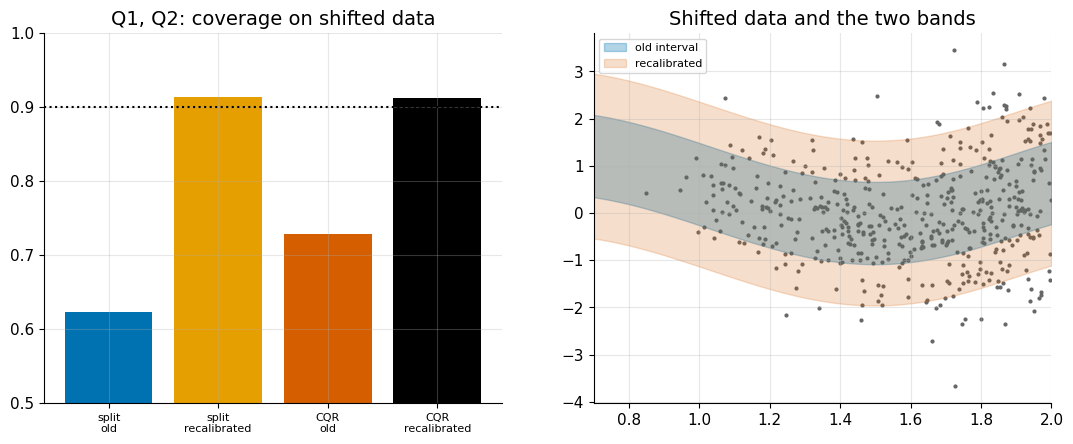

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].bar([0, 1, 2, 3], [c_old, c_new, cq_old, cq_new], color=[MAIN, SIM, HIGHLIGHT, "black"]); axes[0].axhline(0.9, color="black", linestyle=":"); axes[0].set_xticks([0, 1, 2, 3]); axes[0].set_xticklabels(["split\nold", "split\nrecalibrated", "CQR\nold", "CQR\nrecalibrated"], fontsize=8); axes[0].set_ylim(0.5, 1); axes[0].set_title("Q1, Q2: coverage on shifted data")
axes[1].scatter(xs_n[:500], ys_n[:500], s=4, color=NEUTRAL); axes[1].fill_between(xx, mu_c(xx) - qh, mu_c(xx) + qh, color=MAIN, alpha=0.3, label="old interval"); axes[1].fill_between(xx, mu_c(xx) - q_new, mu_c(xx) + q_new, color=HIGHLIGHT, alpha=0.2, label="recalibrated"); axes[1].set_xlim(0.7, 2); axes[1].legend(fontsize=8); axes[1].set_title("Shifted data and the two bands")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- After the shift (inputs concentrated at high $x$, noise 40 % larger) the old intervals cover only **62.3 %** (split conformal) and **72.9 %** (CQR) instead of 90 %: the exchangeability assumption fails, and the guarantee does not apply.
- Recalibrating only the threshold on **300 labelled new cases** restores the coverage to **91.4 %** and **91.3 %**; the model itself is unchanged. The price is the width: the constant half-width doubles (**1.744 to 3.492**) and the mean CQR width goes from 2.260 to 3.495 (its correction $\hat Q$ from 0.018 to 0.636): the new data are really noisier, and the honest interval says so.
- **Decision.** Monitor the empirical coverage of live intervals against the nominal level and recalibrate (or retrain) when it drifts; a drop in coverage is a cheap, label-based drift alarm.

## 13. Where it is used

### Statistics
- **Prediction intervals and tolerance intervals**, nonparametric rank-based inference (the conformal guarantee is the order-statistic argument of 05_07), heteroscedastic regression, **quantile regression**, Bayesian posterior predictive intervals as a comparison, calibration checking.

### Data science
- **Forecasting and pricing with honest intervals**, risk limits and service levels (09_01), A/B-test and demand forecasts with coverage guarantees, **monitoring of interval coverage** after deployment, decision thresholds that depend on interval width.

### ML and AI
- **Uncertainty for deep models** (deep ensembles, MC dropout, 09_06; GPs, 09_10) combined with conformal calibration, **set-valued predictions** in medical imaging and diagnosis, **conformal language modelling** (answer sets with a factuality guarantee), safe reinforcement learning, out-of-distribution detection, and the calibration of probabilities (08_01).

## 14. Common pitfalls and misconceptions

- **Confusing confidence and prediction intervals:** the first is for the mean function (shrinks with data), the second for a new observation (has a floor, Example 2).
- **Assuming constant noise:** a single residual SD gives the right average coverage and the wrong coverage everywhere (Example 1).
- **Calibrating on the training data:** the residuals are optimistic; use a held-out calibration set (or cross-conformal).
- **Reading the guarantee as conditional:** coverage is marginal; it can be low in some regions even when overall 90 % (constant-width conformal).
- **Ignoring distribution shift:** the guarantee needs exchangeability; monitor coverage and recalibrate (Example 4).
- **Too small a calibration set:** with $n=20$ the coverage of one interval ranges widely (Beta spread, 9.3); use at least a few hundred points.
- **Believing a narrow interval means a good model without checking coverage:** report both width and coverage.
- **Confusing set size with error:** a conformal set with 2 classes is not "wrong"; it says the model cannot rule one out at the chosen coverage.

## 15. Exercises

1. With $n=40$ calibration scores and $\alpha=0.1$, which order statistic gives the threshold, and what is the expected coverage?
2. Compute the SD of the conformal coverage for $n=200$ and $\alpha=0.1$ using the Beta formula, and the probability that the coverage falls below 0.88.
3. For a Gaussian prediction with $\hat\sigma=0.5$ and $\sigma_{\text{true}}=0.8$ compute the true coverage of $\hat\mu\pm1.645\hat\sigma$.
4. Re-do Example 1 with $\alpha=0.2$ and report the coverage and width of split conformal and CQR.
5. Fit the heteroscedastic Gaussian model with a *constant* noise head (`ds = 0`) and compare its coverage by region with the version of Example 1.
6. (Harder) Implement **jackknife+** or **cross-conformal** (5 folds) for the degree-5 model and compare the coverage and width with split conformal at equal data.

Solutions are at the end.

## 16. Summary table

| Method | Interval | Guarantee | Adapts to $x$? |
|---|---|---|---|
| Gaussian, one SD | $\hat\mu\pm z\hat\sigma$ | only if the model is right | no |
| Heteroscedastic Gaussian | $\hat\mu(x)\pm z\hat\sigma(x)$ | only if the model is right | yes |
| Split conformal | $\hat\mu\pm\hat q$ | $\ge1-\alpha$, distribution-free | no |
| CQR | $[\hat q_{lo}-\hat Q,\hat q_{hi}+\hat Q]$ | $\ge1-\alpha$ | yes |
| Conformal set | $\{k:1-\hat p_k\le\hat q\}$ | $\ge1-\alpha$ | size adapts |
| Coverage law | Beta$(n+1-l,l)$ | mean $\ge1-\alpha$ | |
| Epistemic | shrinks like $1/\sqrt n$ | | |
| Aleatoric | floor $\sigma(x)$ | | |

## Solutions

In [25]:
k = int(np.ceil(41 * 0.9)); print(f"1: k = ceil(41 x 0.9) = {k}: the {k}-th smallest of 40 scores; expected coverage {k / 41:.4f}")
n2 = 200; l2 = int(np.floor((n2 + 1) * 0.1)); a2, b2 = n2 + 1 - l2, l2; print(f"2: l = {l2}, Beta({a2}, {b2}): mean {a2 / (a2 + b2):.4f}, SD {np.sqrt(a2 * b2 / ((a2 + b2) ** 2 * (a2 + b2 + 1))):.4f}, P(coverage < 0.88) = {stats.beta.cdf(0.88, a2, b2):.4f}")
print(f"3: true coverage = 2 Phi(1.645 x 0.5 / 0.8) - 1 = {2 * stats.norm.cdf(1.645 * 0.5 / 0.8) - 1:.4f}")
res4 = {}
for a_ in (0.2,):
    q_ = conf_q(sc, a_); ql, qu = qreg(xtr, ytr, a_ / 2), qreg(xtr, ytr, 1 - a_ / 2); Qa_ = conf_q(np.maximum(feats(xca, 3) @ ql - yca, yca - feats(xca, 3) @ qu), a_)
    res4["split conformal"] = (np.mean(np.abs(yte - mu_c(xte)) <= q_), 2 * q_); res4["CQR"] = (np.mean((yte >= feats(xte, 3) @ ql - Qa_) & (yte <= feats(xte, 3) @ qu + Qa_)), np.mean(feats(xte, 3) @ (qu - ql) + 2 * Qa_))
print("4: alpha = 0.2 (coverage, mean width):", {k: (round(float(a), 3), round(float(b), 3)) for k, (a, b) in res4.items()})
wc, vc = het_fit(xtr, ytr, ds=0, steps=2500); mc_, sc_ = het_pred(wc, vc, xte, ds=0); cc = (yte >= mc_ - z90 * sc_) & (yte <= mc_ + z90 * sc_); print("5: constant noise head: coverage by region", [round(float(cc[ix == k].mean()), 3) for k in range(5)], "| overall", round(float(cc.mean()), 3), "| heteroscedastic head:", [round(float(((yte >= methods['heteroscedastic Gaussian'][0]) & (yte <= methods['heteroscedastic Gaussian'][1]))[ix == k].mean()), 3) for k in range(5)])
folds = np.array_split(np.random.default_rng(1).permutation(1500), 5); xall, yall = np.concatenate([xtr, xca]), np.concatenate([ytr, yca]); scores = []; models = []
for f in folds: tr = np.setdiff1d(np.arange(1500), f); wf = ols(xall[tr], yall[tr]); models.append(wf); scores.append(np.abs(yall[f] - feats(xall[f], 5) @ wf))
qcc = conf_q(np.concatenate(scores), alpha); mm = np.mean([feats(xte, 5) @ wf for wf in models], axis=0); print(f"6: cross-conformal (5 folds, 1,500 points): coverage {np.mean(np.abs(yte - mm) <= qcc):.3f}, width {2 * qcc:.3f} | split conformal (1,000 + 500): coverage {np.mean(np.abs(yte - mu_c(xte)) <= qh):.3f}, width {2 * qh:.3f}")
assert k == 37 and abs(stats.beta.cdf(0.88, a2, b2)) < 0.5

1: k = ceil(41 x 0.9) = 37: the 37-th smallest of 40 scores; expected coverage 0.9024
2: l = 20, Beta(181, 20): mean 0.9005, SD 0.0211, P(coverage < 0.88) = 0.1638
3: true coverage = 2 Phi(1.645 x 0.5 / 0.8) - 1 = 0.6961


4: alpha = 0.2 (coverage, mean width): {'split conformal': (0.789, 1.284), 'CQR': (0.813, 1.329)}
5: constant noise head: coverage by region [0.999, 0.989, 0.904, 0.815, 0.709] | overall 0.882 | heteroscedastic head: [0.888, 0.883, 0.887, 0.886, 0.889]
6: cross-conformal (5 folds, 1,500 points): coverage 0.885, width 1.728 | split conformal (1,000 + 500): coverage 0.888, width 1.744


**1.** $k=\lceil41\cdot0.9\rceil=$ **37**: the threshold is the **37th smallest of the 40 scores**, and the expected coverage is $37/41=$ **0.9024**.

**2.** $l=\lfloor201\cdot0.1\rfloor=20$, the coverage is Beta(181, 20): mean **0.9005**, SD **0.0211**, and $P(\text{coverage}<0.88)=$ **0.164**: with 200 calibration points a one-in-six chance of landing two points below the target.

**3.** The true coverage is $2\Phi(1.645\cdot0.5/0.8)-1=$ **0.696**: an interval that underestimates the noise by 37 % covers 70 % instead of 90 %.

**4.** For $\alpha=0.2$ split conformal gives coverage **0.789** with mean width 1.284 and CQR **0.813** with width 1.329 (one calibration set; the expected coverage is $\ge0.8$ and a set of 500 points has a spread of about 0.018).

**5.** With a constant noise head the Gaussian model covers **0.999, 0.989, 0.904, 0.815 and 0.709** in the five regions (overall 0.882): the same failure as the constant-width conformal interval; the heteroscedastic head gives 0.883 to 0.889 in all regions.

**6.** Cross-conformal (5 folds, 1,500 points) gives coverage **0.885** and width **1.728**, against 0.888 and 1.744 for split conformal with the same data: slightly narrower at equal coverage, because every point is used for both fitting and calibration.